# Tiled and multiscale points (RFC 3): indexing an existing SpatialData object

This notebook starts from a SpatialData object as it is distributed today (the 10x Atera kidney dataset of
[spatialdata-db](https://www.spatialdata-db.com/collections/10x-atera-whole-transcriptome/), 1.19 billion transcripts)
and writes its points again with the spatial index of
[RFC 3](https://spatialdata-spec.scverse.org/rfcs/0003-tiled-points.html): a random priority $p$ per point, levels
as bands, a tile-major table and a feature-major table, and their offsets. It then reads them back by region, level,
budget and gene, and compares with reading without an index.

The API is experimental (draft PR on `LucaMarconato/spatialdata`, branch `tiled-points-spatial-index`).

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import spatialdata as sd
from spatialdata._io.spatial_index import PointsSpatialIndex, write_points_with_spatial_index

DATA = Path("/Users/macbook/embl/projects/basel/tiled-index-data")
SOURCE = DATA / "spatialdata_db_atera_kidney.zarr"  # points, shapes and table downloaded from spatialdata-db
OUT = DATA / "kidney.zarr"

## The SpatialData object as distributed

In [2]:
sdata = sd.read_zarr(SOURCE, selection=("points", "shapes", "tables"))  # images were not downloaded
sdata

/Users/macbook/embl/projects/basel/spatialdata-tiled-index/src/spatialdata/_core/spatialdata.py:173: UserWarning: The table is annotating 'cell_labels', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(table)


SpatialData object, with associated Zarr store: /Users/macbook/embl/projects/basel/tiled-index-data/spatialdata_db_atera_kidney.zarr
├── Points
│     └── 'transcripts': DataFrame with shape: (1186813834, 7) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (399120, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (398197, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (399120, 24674)
with coordinate systems:
    ▸ 'global', with elements:
        transcripts (Points), cell_boundaries (Shapes), nucleus_boundaries (Shapes)
with the following elements in the Zarr store but not in the SpatialData object:
    ▸ he_image (Images)
    ▸ morphology (Images)
    ▸ cell_labels (Labels)
    ▸ nucleus_labels (Labels)

In [3]:
points = sdata["transcripts"]
print(points.npartitions, "partitions")
points.dtypes

256 partitions


x                   float32
y                   float32
z                   float32
feature_name         string
cell_id               int64
overlaps_nucleus       bool
quality_score       float32
dtype: object

The feature column (`feature_name`) is a plain string column here; the builder turns it into a categorical with a
global category list (RFC 3: "integer codes with the category list stored once").

## A new store with the other elements

The index is written as a new points element; here we put it in a new store, next to the shapes and the table, and
leave the downloaded dataset untouched. `sd.build_points_spatial_index(sdata, name)` would instead rewrite the
element in place (or under `new_element_name`).

In [4]:
if not OUT.exists():
    sd.SpatialData(shapes=dict(sdata.shapes), tables=dict(sdata.tables)).write(OUT)

## Building the index

Both formats of RFC 3: Parquet (points format 0.3, the default) and Zarr (0.3-experimental), with the same layout.
The grid has all the axes of the points (x, y and a single tile along z); the tile size is chosen so that the
median non-empty tile of level 0 holds about 10,000 points; the levels follow the merge rule and the default rates;
p is stored as 16-bit integers; Parquet row groups hold several tiles (at least 250,000 rows).

The builder works out of core: it reads the points partition by partition, scatters them to temporary buckets and
sorts each bucket in memory.

In [5]:
stats_by_storage = {}
for storage in ["parquet", "zarr"]:
    name = f"transcripts_{storage}"
    path = OUT / "points" / name
    if not (path / "zarr.json").exists() or "spatial_index" not in (path / "zarr.json").read_text():
        t0 = time.time()
        md, stats = write_points_with_spatial_index(
            points, path, storage=storage, tmp_dir=DATA / "tmp", n_workers=6
        )
        stats_by_storage[storage] = stats
        print(storage, f"{time.time() - t0:.0f} s")
sd.SpatialData.read(OUT).write_consolidated_metadata()

parquet 1240 s


/Users/macbook/embl/projects/basel/spatialdata-tiled-index/src/spatialdata/_core/spatialdata.py:173: UserWarning: The table is annotating 'cell_labels', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(table)


In [6]:
index = PointsSpatialIndex(OUT / "points" / "transcripts_parquet")
md = index.metadata
for l, lv in enumerate(md.levels):
    print(l, "tile", [round(s, 1) for s in lv.tile_size], "grid", lv.grid_shape, "P", round(lv.P, 6))
print("p_bits", md.p_bits)

0 tile [28.4, 28.4, 21.0] grid (424, 249, 1) P 1.0
1 tile [56.8, 56.8, 21.0] grid (212, 125, 1) P 0.25
2 tile [113.6, 113.6, 21.0] grid (106, 63, 1) P 0.0625
3 tile [227.2, 227.2, 21.0] grid (53, 32, 1) P 0.015625
4 tile [454.5, 454.5, 21.0] grid (27, 16, 1) P 0.003906
5 tile [909.0, 909.0, 21.0] grid (14, 8, 1) P 0.000977
6 tile [1817.9, 1817.9, 21.0] grid (7, 4, 1) P 0.000244
p_bits 16


The element reads as a normal points element (tile-major order, with the extra column `__spatialdata_p__`):

In [7]:
sdata_tiled = sd.read_zarr(OUT)
sdata_tiled["transcripts_parquet"].head()

/Users/macbook/embl/projects/basel/spatialdata-tiled-index/src/spatialdata/_core/spatialdata.py:173: UserWarning: The table is annotating 'cell_labels', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(table)


,x,y,z,feature_name,__spatialdata_p__,cell_id,overlaps_nucleus,quality_score
0,1376.390625,1495.937500,11.421875,ABCA6,0,-1,False,40.00
1,443.218750,1217.328125,13.312500,ADAM33,0,5137322723,False,40.00
2,652.062500,1253.375000,12.156250,ANTKMT,0,4318075345,True,29.00
3,819.218750,1477.921875,10.906250,AP3B1,0,-1,False,40.00
4,439.046875,1217.890625,11.937500,C3,0,5137322723,False,26.25


## Reading by region, level and budget

`query(box_min, box_max, level=...)` reads the bands $L, \dots, l$ of the tiles in view. With a budget $b$ it reads
the points with $p < b$: a uniform sample, which is a prefix of each tile.

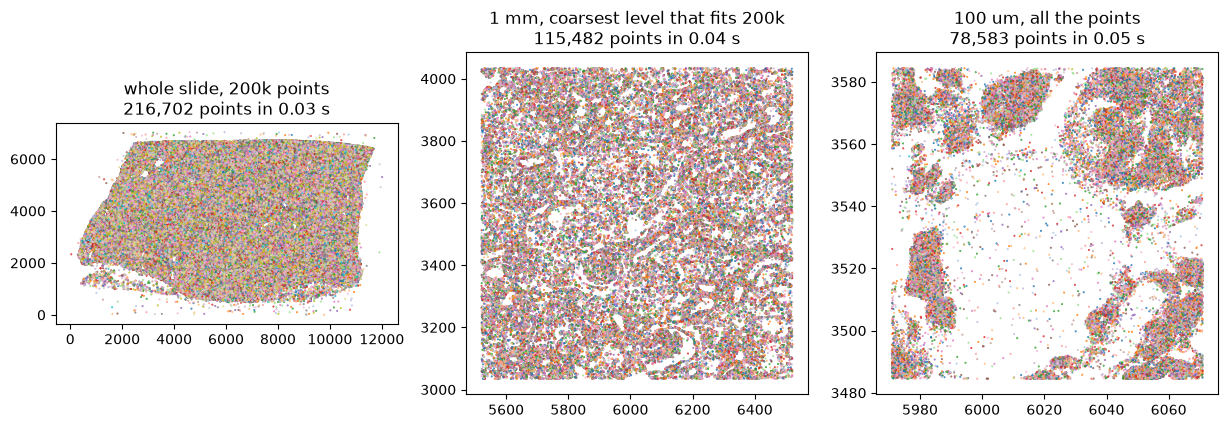

In [8]:
lv0 = md.levels[0]
origin = np.array(lv0.origin)
extent = np.array(lv0.tile_size) * np.array(lv0.grid_shape)
center = origin + extent / 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, box, kw) in zip(axes, [
    ("whole slide, 200k points", (None, None), {"budget": 200_000 / index.n_rows}),
    ("1 mm, coarsest level that fits 200k", (center - 500, center + 500), {"budget": 200_000 / 3e7}),
    ("100 um, all the points", (center - 50, center + 50), {}),
]):
    t0 = time.time()
    df = index.query(*box, columns=["x", "y", "feature_name"], **kw)
    ax.scatter(df.x, df.y, s=0.2, c=df.feature_name.cat.codes, cmap="tab20", rasterized=True)
    ax.set_title(f"{title}\n{len(df):,} points in {time.time() - t0:.2f} s")
    ax.set_aspect("equal")
plt.show()

## Reading genes: feature-major vs tile-major

In [9]:
counts = index.feature_ranges("feature_name", range(len(index.categories("feature_name"))))
s, e = counts
cats = index.categories("feature_name")
per_gene = (e - s).reshape(md.n_levels, len(cats)).sum(axis=0)
rare = cats[int(np.argsort(per_gene)[len(cats) // 10])]
common = cats[int(np.argmax(per_gene))]
print("rare:", rare, per_gene[cats.index(rare)], "common:", common, per_gene[cats.index(common)])

rare: NegControlCodeword_41810 85 common: C7 2619461


In [10]:
for gene in [rare, common]:
    for use_feature_index in [True, False]:
        t0 = time.time()
        df = index.query(center - 1000, center + 1000, features=[gene], use_feature_index=use_feature_index,
                         columns=["x", "y", "feature_name"])
        print(f"{gene:>12} feature-major={use_feature_index!s:5} {len(df):>9,} points {time.time() - t0:6.2f} s")

NegControlCodeword_41810 feature-major=True          3 points   0.05 s


NegControlCodeword_41810 feature-major=False         3 points   1.21 s
          C7 feature-major=True     89,509 points   0.08 s


          C7 feature-major=False    89,509 points   0.98 s


## Without an index

For comparison, dask with Parquet filters on the original element (the row groups of the original are not sorted
spatially, so statistics prune little).

In [11]:
import dask.dataframe as dd

src = SOURCE / "points" / "transcripts" / "points.parquet"
lo, hi = center - 50, center + 50
t0 = time.time()
n = len(dd.read_parquet(src, columns=["x", "y"], filters=[("x", ">=", lo[0]), ("x", "<=", hi[0]),
                                                        ("y", ">=", lo[1]), ("y", "<=", hi[1])]))
print(f"no index: {n:,} points in {time.time() - t0:.1f} s")
t0 = time.time()
n = len(index.query(lo, hi, columns=["x", "y"]))
print(f"index:    {n:,} points in {time.time() - t0:.2f} s")

no index: 78,583 points in 0.5 s
index:    78,583 points in 0.02 s


## Zarr storage

The same index with the points as a `df:` Zarr group (`spatial/points`, sharded), read the same way.

In [12]:
zindex = PointsSpatialIndex(OUT / "points" / "transcripts_zarr")
t0 = time.time()
df = zindex.query(center - 500, center + 500, budget=0.05, columns=["x", "y", "feature_name"])
print(f"{len(df):,} points in {time.time() - t0:.2f} s")

867,797 points in 0.13 s


## In napari

With the napari-spatialdata branch `tiled-points-spatial-index`, the indexed element loads only the points in view,
sampled down to `config.POINT_THRESHOLD`, and reloads them when the camera moves:

```python
from napari_spatialdata import Interactive
Interactive(sd.read_zarr(OUT))
```